# [기초-실습] 통계 101×데이터 분석: (7장) 상관과 회귀

_이 노트북은 LMS에서 내보냈습니다. 영상·퀴즈는 학습 참고용으로 마크다운으로 변환되었습니다._

## ⚙️ 환경 준비

### 1단계 · 한글 폰트 설치

- 그래프에 한글이 깨지지 않도록 나눔 폰트를 설치합니다.

- 실행 후 **[런타임] - [세션 다시 시작]**을 한 번 눌러야 폰트가 적용됩니다.

In [1]:
# 구글 코랩 환경에서 한글 폰트 설치 및 설정하기
# 필요시 아래 코드 실행 후, [런타임] - [세션 다시 시작] 후 셀을 다시 실행하세요.
!pip install statsmodels
!sudo apt-get install -y fonts-nanum
!sudo fc-cache -fv
!rm ~/.cache/matplotlib -rf

Reading package lists...
Building dependency tree...
Reading state information...
fonts-nanum is already the newest version (20200506-1).
0 upgraded, 0 newly installed, 0 to remove and 0 not upgraded.
Font directories:
	/root/.local/share/fonts
	/usr/local/share/fonts
	/usr/share/fonts
	/root/.fonts
	/usr/share/fonts/truetype
	/usr/share/fonts/truetype/humor-sans
	/usr/share/fonts/truetype/liberation
	/usr/share/fonts/truetype/nanum
/root/.local/share/fonts: skipping, no such directory
/usr/local/share/fonts: caching, new cache contents: 0 fonts, 0 dirs
/usr/share/fonts: caching, new cache contents: 0 fonts, 1 dirs
/usr/share/fonts/truetype: caching, new cache contents: 0 fonts, 3 dirs
/usr/share/fonts/truetype/humor-sans: caching, new cache contents: 1 fonts, 0 dirs
/usr/share/fonts/truetype/liberation: caching, new cache contents: 12 fonts, 0 dirs
/usr/share/fonts/truetype/nanum: caching, new cache contents: 12 fonts, 0 dirs
/root/.fonts: skipping, no such directory
/usr/share/fonts/

### 2단계 · 라이브러리 불러오기

- 이번 실습에서 쓰는 도구입니다. **한 번만 실행**해 두면 끝까지 사용합니다.

- `smf`는 회귀식을 `'y ~ x'` 형태로 쓰는 모듈, `het_breuschpagan`은 등분산 검정 함수입니다.

In [2]:
# 파이썬 라이브러리 및 모듈 가져오기
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.diagnostic import het_breuschpagan
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.family'] = 'NanumGothic'  # 기본 폰트 설정
plt.rcParams['axes.unicode_minus'] = False   # 마이너스 기호 깨짐 방지

## 문제 1 · 펭귄의 부리는 길수록 두꺼울까?

`난이도 하` · `예상 15분`

**📖 상황**

- 남극 팔머 기지에서 측정한 펭귄 344마리의 신체 데이터(`penguins`)를 사용합니다.

- 부리 길이(`bill_length_mm`)와 부리 두께(`bill_depth_mm`)가 함께 어떻게 움직이는지 봅니다.

- 그런데 이 데이터에는 **세 종(Adelie·Chinstrap·Gentoo)이 섞여 있습니다.**
  전체를 뭉쳐서 볼 때와 집단을 나눠서 볼 때 **결론이 정반대로 뒤집히는 일**이 실제로 일어납니다.

**🎯 이 문제로 배우는 것**

- 상관계수를 계산하기 **전에** 산점도를 먼저 그려야 하는 이유를, 숫자로 직접 확인합니다.

In [3]:
# 문제 1 · 데이터 준비 — 실행만 하세요
penguins = sns.load_dataset('penguins')

print("데이터 크기:", penguins.shape)
print("\n종별 개체 수:")
print(penguins['species'].value_counts())
print("\n결측치 개수:")
print(penguins.isna().sum())

penguins.head()

데이터 크기: (344, 7)

종별 개체 수:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

결측치 개수:
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64
  species     island  bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g     sex
0  Adelie  Torgersen            39.1           18.7              181.0       3750.0    Male
1  Adelie  Torgersen            39.5           17.4              186.0       3800.0  Female
2  Adelie  Torgersen            40.3           18.0              195.0       3250.0  Female
3  Adelie  Torgersen             NaN            NaN                NaN          NaN     NaN
4  Adelie  Torgersen            36.7           19.3              193.0       3450.0  Female


### Q1 · 산점도로 두 변수의 관계를 그려 봅시다

- 가로축 `bill_length_mm`, 세로축 `bill_depth_mm`로 산점도를 그리세요.

- 그래프 제목과 축 라벨을 한글로 알아보기 쉽게 설정하세요.

- `💡 힌트` `sns.scatterplot(data=..., x=..., y=...)` / `plt.title()`, `plt.xlabel()`, `plt.ylabel()`

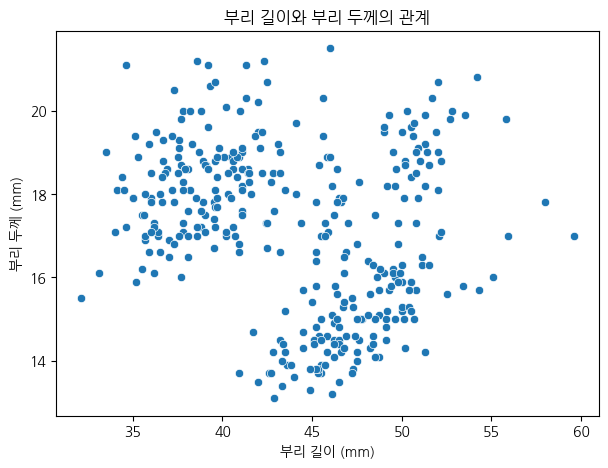

In [4]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm')
plt.title('부리 길이와 부리 두께의 관계')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q2 · 종별로 색을 나눠 같은 그림을 다시 그려 봅시다

- Q1과 똑같은 산점도에 펭귄의 종(`species`)별로 점의 색을 다르게 칠하세요.

- Q1의 그림과 나란히 놓고 무엇이 달라 보이는지 관찰하세요.

- `💡 힌트` `sns.scatterplot()`에 `hue` 인수를 추가해 보세요.

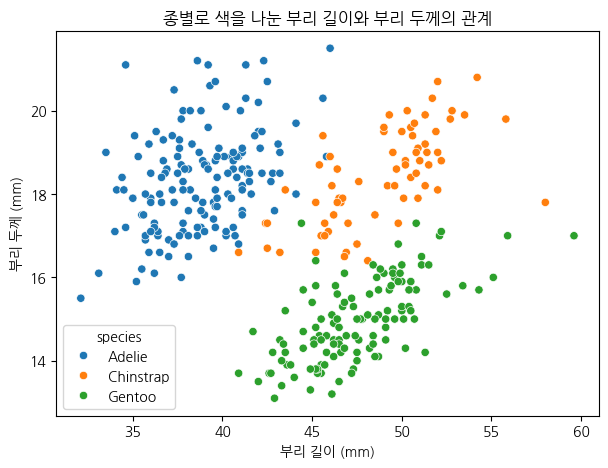

In [5]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species')
plt.title('종별로 색을 나눈 부리 길이와 부리 두께의 관계')
plt.xlabel('부리 길이 (mm)')
plt.ylabel('부리 두께 (mm)')
plt.show()

### Q3 · 상관계수를 '전체'와 '종별'로 각각 구해 비교해 봅시다

- 두 변수의 상관계수를 **전체 데이터**에 대해 계산하세요.

- 같은 상관계수를 **종별로 나누어** 계산하세요.

- 두 결과의 **부호**를 비교하세요.

- `💡 힌트` 전체는 `df[['A','B']].dropna().corr()`,
  종별은 `df.groupby('species')[['A','B']].corr()`를 활용해 보세요.

In [6]:
cols = ['bill_length_mm', 'bill_depth_mm']
print('[전체 상관계수]')
print(penguins[cols].dropna().corr())
print()
print('[종별 상관계수]')
print(penguins.groupby('species')[cols].corr())

[전체 상관계수]
                bill_length_mm  bill_depth_mm
bill_length_mm        1.000000      -0.235053
bill_depth_mm        -0.235053       1.000000

[종별 상관계수]
                          bill_length_mm  bill_depth_mm
species                                                
Adelie    bill_length_mm        1.000000       0.391492
          bill_depth_mm         0.391492       1.000000
Chinstrap bill_length_mm        1.000000       0.653536
          bill_depth_mm         0.653536       1.000000
Gentoo    bill_length_mm        1.000000       0.643384
          bill_depth_mm         0.643384       1.000000


### 💬 정리 · 결과를 말로 설명해 보기

- Q1의 산점도에서 두 변수는 어떤 방향의 관계로 보였나요? Q3의 전체 상관계수와 부호가 일치하나요?

- Q3의 종별 상관계수는 전체와 부호가 같나요, 다른가요?

- **같은 데이터인데 전체와 집단별 결론이 정반대로 나온 이유**를 설명해 보세요. 무엇이 이 착시를 만들고 있나요?

- 만약 이 데이터에 '종' 정보가 없었다면 우리는 어떤 잘못된 결론을 내렸을까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 부호가 뒤집히는 열쇠는 **종마다 부리의 '기본 크기'가 다르다**는 데 있습니다. 종별 평균이 어디에 놓여 있는지를 Q2의 그림에서 확인해 보세요.

- "전체를 보면 음, 나누면 양"은 두 변수 사이에 **숨은 집단 변수**가 끼어 있을 때 나타납니다. 이 현상에는 이름이 붙어 있고, 다음 시간 인과추론에서 다시 만납니다.

- 결론의 형태를 이렇게 나눠 써 보면 정확해집니다 — "종을 무시하면 ○○, 종을 고려하면 ○○".

</details>

In [35]:
# 문제 1 · 정리
# 1) Q1 산점도는 한 방향으로 분명하지 않고 점이 여기저기 퍼져 있었다. 전체적으로는 약하게 내려가는 경향(음의 관계)이고, Q3 전체 상관계수도 약 -0.235로 음수다. 그림의 경향과 숫자의 부호가 일치한다.
# 2) 종별 상관계수는 Adelie 약 0.39, Chinstrap 약 0.65, Gentoo 약 0.64로 세 종 모두 양수다. 전체(음수)와 부호가 다르다.
# 3) 종마다 부리 크기가 다르기 때문이다. Gentoo는 부리가 길고 얇고, Adelie는 짧고 두꺼운 편이다. 세 종을 섞으면 종 사이의 차이가 전체 방향을 음으로 끌고 간다. 같은 종 안에서는 부리가 길수록 두꺼운 양의 관계다. 숨은 변수(종)가 만든 착시이고 이런 현상을 심프슨의 역설이라고 부른다.
# 4) 종 정보가 없었다면 '부리가 길수록 두께는 얇아진다'라는 잘못된 결론을 냈을 것이다. 그래서 상관계수를 구하기 전에 산점도를 그리고 집단을 나눠 봐야 한다.

## 문제 2 · 날개가 길면 몸무게도 무거울까? — 관계를 숫자로

`난이도 하` · `예상 20분`

**📖 상황**

- 문제 1에서 "숫자 전에 그림"을 배웠습니다. 이제 관계를 **숫자 하나**로 요약해 봅니다.

- 이번에는 **날개 길이(`flipper_length_mm`)와 몸무게(`body_mass_g`)**를 봅니다.
  이 두 변수는 **문제 5까지 계속 사용**하며, 상관 → 회귀 → 검정 → 진단으로 이어집니다.

- **피어슨 상관계수(r)**는 관계의 방향(부호)과 강도(절대값)를 −1~+1로 나타냅니다.
  다만 피어슨은 **두 변수가 정규분포라는 전제**에 기대는 모수적 방법입니다.

**🎯 이 문제로 배우는 것**

- 정규성 점검 → 피어슨(r과 p-값) → 스피어만 비교의 순서로, **강의에서 배운 절차 그대로** 상관을 구합니다.

결측치 제거 전: 344 행
결측치 제거 후: 342 행


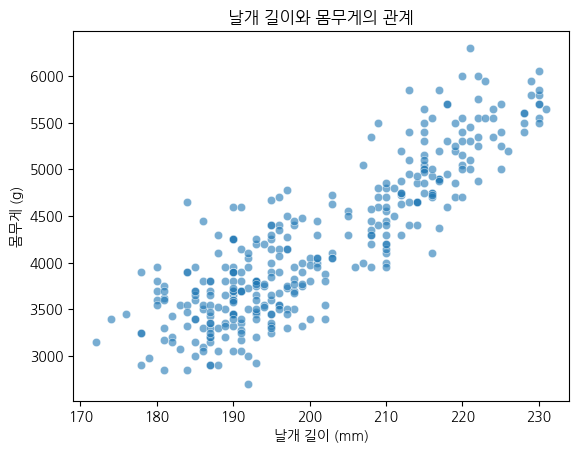

In [7]:
# 문제 2 · 데이터 준비 — 실행만 하세요
df_corr = penguins[['flipper_length_mm', 'body_mass_g']].dropna()

print("결측치 제거 전:", len(penguins), "행")
print("결측치 제거 후:", len(df_corr), "행")

# 두 변수의 관계를 그림으로 먼저 확인 (문제 1의 교훈!)
sns.scatterplot(data=df_corr, x='flipper_length_mm', y='body_mass_g', alpha=0.6)
plt.title("날개 길이와 몸무게의 관계")
plt.xlabel("날개 길이 (mm)")
plt.ylabel("몸무게 (g)")
plt.show()

### Q1 · 피어슨의 전제인 정규성을 점검해 봅시다

- `flipper_length_mm`과 `body_mass_g` **각각**에 대해 정규성 검정(Shapiro-Wilk)을 수행하세요.

- 유의수준 0.05를 기준으로 '정규성을 기각하는지'까지 함께 출력하세요.

- `💡 힌트` `stats.shapiro(데이터)`는 통계량과 p-값을 함께 돌려줍니다.

In [8]:
alpha = 0.05
stat_f, p_f = stats.shapiro(df_corr['flipper_length_mm'])
stat_b, p_b = stats.shapiro(df_corr['body_mass_g'])
print(f'날개 길이: 통계량={stat_f:.4f}, p-값={p_f:.4g}, 정규성 기각 여부={p_f < alpha}')
print(f'몸무게  : 통계량={stat_b:.4f}, p-값={p_b:.4g}, 정규성 기각 여부={p_b < alpha}')

날개 길이: 통계량=0.9515, p-값=3.54e-09, 정규성 기각 여부=True
몸무게  : 통계량=0.9592, p-값=3.679e-08, 정규성 기각 여부=True


### Q2 · 피어슨 상관계수와 p-값을 함께 구해 봅시다

- 상관계수만이 아니라 **p-값도 함께** 구하세요. 상관계수도 가설검정의 대상입니다.

- 결과는 반드시 `r`, `p_value`라는 이름으로 저장하세요. **문제 3·4에서 이어서 사용합니다.**

- `💡 힌트` `r, p_value = stats.pearsonr(x, y)` — 귀무가설은 "모집단의 상관계수가 0이다"입니다.

In [9]:
r, p_value = stats.pearsonr(df_corr['flipper_length_mm'], df_corr['body_mass_g'])
print(f'피어슨 상관계수 r = {r:.4f}')
print(f'p-값 = {p_value:.4g}')

피어슨 상관계수 r = 0.8712
p-값 = 4.371e-107


### Q3 · 스피어만 상관계수를 구해 피어슨과 비교해 봅시다

- 스피어만 상관계수(ρ)를 구하세요.

- Q2의 피어슨 값과 **나란히 출력**해 두 값의 차이를 눈으로 확인하세요.

- `💡 힌트` `stats.spearmanr(x, y)`

In [10]:
rho, p_sp = stats.spearmanr(df_corr['flipper_length_mm'], df_corr['body_mass_g'])
print(f'피어슨 r      = {r:.4f}')
print(f'스피어만 rho  = {rho:.4f} (p-값 = {p_sp:.4g})')
print(f'두 값의 차이  = {abs(r - rho):.4f}')

피어슨 r      = 0.8712
스피어만 rho  = 0.8400 (p-값 = 2.763e-92)
두 값의 차이  = 0.0312


### Q4 · 세 결과를 종합해 관계를 문장으로 정리해 봅시다

- Q1~Q3의 결과를 근거로, 오른쪽 빈칸을 채워 관계를 정리하세요.

- 숫자만 적지 말고 **그 숫자가 뜻하는 바**를 함께 쓰세요.

In [11]:
# 문제 2 · Q4
# 정규성 검정 결과 (피어슨의 전제가 지켜졌나요?): 날개 길이와 몸무게 모두 p-값이 0.05보다 작아 정규성을 기각한다. 즉 두 변수 모두 정규분포라고 보기 어렵다.
# 피어슨 r 값과 p-값: r = 0.8712, p-값은 거의 0(약 4e-107)이다. 상관계수가 0이라는 귀무가설을 기각한다. 즉 우연으로 보기 어려운 관계다.
# 스피어만 p 값: rho = 0.8400, p-값은 거의 0이다. 순위로 계산해도 관계가 유의하다.
# 부호(+/-)가 뜻하는 관계의 방향: 부호가 +이므로 날개가 길수록 몸무게도 무거워지는 방향이다.
# 절대값의 크기가 뜻하는 관계의 정도: 0.87은 1에 가까워 매우 강한 관계다. 피어슨(0.87)과 스피어만(0.84)이 비슷해서 정규성이 깨졌어도 결론은 같다.

### 💬 정리 · 결과를 말로 설명해 보기

- Q1에서 정규성이 기각되었습니다. 그렇다면 피어슨 상관계수를 쓰면 안 되는 걸까요? Q2와 Q3의 값을 비교해서 판단해 보세요.

- 피어슨과 스피어만이 비슷하게 나왔다는 것은 무엇을 뜻할까요? 만약 두 값이 크게 달랐다면 어떤 상황을 의심해야 할까요?

- Q2의 p-값은 무엇에 대한 검정인가요? "상관계수가 크다"와 "상관계수가 유의하다"는 같은 말인가요?

- '날개가 길어지는 것이 몸무게를 무겁게 만드는 **원인**이다'라고 결론 내릴 수 있을까요? **교란변수 / 역인과 / 우연** 세 가지로 나누어 설명해 보세요.

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 정규성이 깨졌을 때 확인할 것은 "쓰면 안 되나"가 아니라 **"결론이 바뀌는가"**입니다. 두 계수가 거의 같다면 전제 위배의 영향이 작다는 뜻이고, 크게 다르면 이상치나 비선형을 의심합니다.

- p-값은 관계의 **크기**가 아니라 **존재**에 대한 답입니다. 표본이 커지면 아주 작은 상관도 유의해집니다 — 두 질문을 분리해서 답해 보세요.

- 인과를 부정하는 세 갈래를 이 데이터에 대입해 보세요. 교란변수 후보는 문제 1에서 이미 만났습니다.

</details>

In [31]:
# 문제 2 · 정리
# 1) 정규성이 기각됐다고 피어슨을 못 쓰는 것은 아니다. 피어슨은 정규분포를 전제로 하지만, 스피어만(0.84)과 피어슨(0.87) 값이 비슷하게 나왔으므로 피어슨 결과를 써도 결론이 달라지지 않는다.
# 2) 두 값이 비슷하다는 것은 관계가 이상치나 이상한 모양 때문에 만들어진 게 아니라 전체적으로 안정적이라는 뜻이다. 만약 두 값이 크게 달랐다면 이상치(튀는 값)나 직선이 아닌 휘어진 관계를 의심해야 한다.
# 3) Q2의 p-값은 '모집단의 상관계수가 0이다'라는 귀무가설에 대한 검정이다. 상관계수가 크다는 것은 관계의 세기이고, 유의하다는 것은 우연이 아닐 가능성이 크다는 뜻이라서 같은 말이 아니다. 표본이 많으면 작은 상관계수도 유의하게 나올 수 있다.
# 4) 날개가 길어서 몸무게가 무거워진다고 단정할 수 없다. 교란변수: 종이나 성별 같은 제3의 요인이 둘 다에 영향을 줄 수 있다. 역인과: 몸이 무거운 펭귄이 날개도 크게 자랐을 수도 있다. 우연: 표본에서 우연히 그렇게 나왔을 수도 있다. 상관은 인과가 아니다.

## 문제 3 · 그 관계를 하나의 식으로 만들 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 상관계수는 "관계가 얼마나 **강한가**"만 알려주고, "날개가 1mm 길면 몸무게가 **몇 g** 늘어나는가"는
  말해주지 않습니다. 그 답을 주는 것이 **선형회귀(Linear Regression)**입니다.

- 흩어진 점들을 가장 잘 가로지르는 직선 `y = a + bx`를 찾아 관계를 하나의 **식**으로 표현합니다.
  `a`(절편)는 x가 0일 때의 예측값, `b`(기울기)는 **x가 1 늘 때 y가 평균적으로 변하는 양**입니다.

- 그런데 상관과 회귀는 **서로 남이 아닙니다.** 문제 2에서 구한 `r`과
  이번에 구할 기울기·결정계수 사이에는 정확한 관계식이 성립합니다.

**🎯 이 문제로 배우는 것**

- 회귀식을 적합·해석하고, **상관과 회귀가 한 뿌리임을 숫자로 확인**합니다.

In [12]:
# 문제 3 · 데이터 준비 — 실행만 하세요
penguins_cleaned = penguins.dropna(subset=['body_mass_g', 'flipper_length_mm'])

print("분석에 사용할 데이터:", len(penguins_cleaned), "행")
print("문제 2의 df_corr과 동일한가?:", len(penguins_cleaned) == len(df_corr))

분석에 사용할 데이터: 342 행
문제 2의 df_corr과 동일한가?: True


### Q1 · 단순회귀 모델을 적합해 봅시다

- **날개 길이(설명변수) → 몸무게(반응변수)** 회귀 모델을 적합하세요.

- 적합한 모델은 반드시 `model`이라는 이름으로 저장하세요. **문제 4·5에서 이어서 사용합니다.**

- `💡 힌트` `model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=...).fit()`

In [13]:
model = smf.ols(formula='body_mass_g ~ flipper_length_mm', data=penguins_cleaned).fit()
print('모델 적합 완료')
print(model.params)

모델 적합 완료
Intercept           -5780.831358
flipper_length_mm      49.685566
dtype: float64


### Q2 · 분석 결과표를 출력해 봅시다

- 적합한 모델의 요약 결과표를 출력하세요.

- `coef`, `P>|t|`, `R-squared` 열이 각각 어디에 있는지 눈으로 찾아 두세요. 다음 문제들에서 계속 씁니다.

- `💡 힌트` 모델 객체의 `.summary()` 메소드를 사용하세요.

In [14]:
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:            body_mass_g   R-squared:                       0.759
Model:                            OLS   Adj. R-squared:                  0.758
Method:                 Least Squares   F-statistic:                     1071.
Date:                Wed, 04 Nov 2026   Prob (F-statistic):          4.37e-107
Time:                        05:48:09   Log-Likelihood:                -2528.4
No. Observations:                 342   AIC:                             5061.
Df Residuals:                     340   BIC:                             5069.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept         -5780.8314    305.81

### Q3 · 회귀식을 완성해 봅시다

- Q2의 결과표에서 **절편**과 **기울기**를 찾아 오른쪽 빈칸을 채우세요.

- 숫자를 옮겨 적은 뒤, 완성된 식을 한 줄로 써 보세요.

In [15]:
# 문제 3 · Q3
# 절편(a) 값: -5780.83
# 기울기(b) 값: 49.69
# 완성된 회귀식 → 몸무게(g) = -5780.83 + 49.69 × 날개길이(mm)
print(f"몸무게(g) = {model.params['Intercept']:.2f} + {model.params['flipper_length_mm']:.2f} × 날개길이(mm)")

몸무게(g) = -5780.83 + 49.69 × 날개길이(mm)


### Q4 · 회귀식으로 예측해 봅시다

- 날개 길이가 평균보다 **10mm 더 긴** 펭귄은, 평균적인 펭귄보다 몸무게가 몇 g 더 무거울까요?

- 계산 결과를 단위(g)와 함께 출력하세요.

- `💡 힌트` 기울기 × 10

In [17]:
slope = model.params['flipper_length_mm']
print(f'날개가 평균보다 10mm 더 긴 펭귄은 평균적으로 몸무게가 {slope * 10:.1f} g 더 무겁다.')

날개가 평균보다 10mm 더 긴 펭귄은 평균적으로 몸무게가 496.9 g 더 무겁다.


### Q5 · 상관과 회귀를 잇는 두 관계식을 확인해 봅시다

- 다음 두 식이 실제로 성립하는지 **숫자로** 확인하세요.
  - ① 기울기 = `r` × (y의 표준편차 / x의 표준편차)
  - ② 결정계수 `R²` = `r²` _(단순회귀에서만 성립)_

- 좌변과 우변을 **나란히 출력**해 두 값이 일치하는지 눈으로 확인하세요.

- `💡 힌트` 문제 2 Q2의 `r`을 사용합니다. 표준편차는 `.std(ddof=1)`, 모델의 R²는 `model.rsquared`입니다.

In [16]:
sd_y = penguins_cleaned['body_mass_g'].std(ddof=1)
sd_x = penguins_cleaned['flipper_length_mm'].std(ddof=1)
print(f"① 기울기(모델)        = {model.params['flipper_length_mm']:.4f}")
print(f'① r × (y의 표준편차 / x의 표준편차) = {r * sd_y / sd_x:.4f}')
print(f'② 결정계수 R²(모델)   = {model.rsquared:.4f}')
print(f'② r²                = {r ** 2:.4f}')

① 기울기(모델)        = 49.6856
① r × (y의 표준편차 / x의 표준편차) = 49.6856
② 결정계수 R²(모델)   = 0.7590
② r²                = 0.7590


### 💬 정리 · 결과를 말로 설명해 보기

- 기울기(b) 값을 "날개 길이가 ○○할 때 몸무게가 ○○한다"는 문장으로 풀어 써 보세요.

- 절편(a)이 음수로 나왔습니다. 이 숫자를 "날개 길이가 0mm인 펭귄의 몸무게"로 해석해도 될까요? 왜 그럴까요?

- Q5에서 `R² = r²`을 확인했습니다. 그렇다면 설명변수와 반응변수를 서로 바꿔 분석하면 **기울기**와 **R²**는 각각 같을까요, 다를까요?

- 상관계수 `r`은 단위 없는 −1~1 값이고, 기울기 `b`는 'mm당 g'이라는 단위를 가집니다. 회귀가 상관보다 더 알려주는 것은 무엇인가요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 절편은 **데이터가 존재하는 범위 밖의 값**입니다. 날개 길이 0mm인 펭귄은 우리 데이터에 없습니다 — 회귀식은 관측 범위 안에서만 의미를 갖습니다.

- x와 y를 바꿨을 때를 생각할 때 기준은 **"r은 대칭인가, s_y/s_x는 대칭인가"**입니다. 두 관계식 ①②를 각각 대입해 보면 답이 갈립니다.

- "강도"와 "변화량"의 차이로 정리해 보세요. 보고서에 "1mm당 ○g"을 쓸 수 있는 쪽은 어느 것인가요?

</details>

In [32]:
# 문제 3 · 정리
# 1) 기울기 b = 49.69 → 날개 길이가 1mm 길어질 때 몸무게는 평균적으로 약 49.7g 무거워진다.
# 2) 절편이 -5780g이다. 날개 길이가 0mm인 펭귄은 없고 데이터 범위(약 172~231mm) 밖이라서 이 값은 직선을 계산하기 위한 숫자일 뿐이다. 몸무게가 음수일 수 없으니 실제 의미로 해석하면 안 된다.
# 3) 설명변수와 반응변수를 바꾸면 기울기는 달라지지만 R²는 같다. R²는 r²이고 r은 x와 y를 바꿔도 같기 때문이다. 기울기는 y가 x에 얼마나 변하는지라서 방향이 바뀌면 값도 바뀐다.
# 4) 상관계수는 관계가 얼마나 강한지(단위 없음)만 알려준다. 회귀는 x가 1 변할 때 y가 몇 g 변하는지 구체적인 크기를 알려주고, 새 값을 넣어 예측까지 할 수 있다.

## 문제 4 · 이 기울기, 우연이 아니라고 말할 수 있을까?

`난이도 중` · `예상 25분`

**📖 상황**

- 문제 3에서 기울기를 구했습니다. 그런데 이 값은 **표본 342마리에서 계산된 값**입니다.

- 만약 전체 펭귄 집단에서 두 변수가 실제로는 아무 관계가 없다면(**기울기 = 0**),
  우리가 얻은 기울기는 그저 **표본을 뽑는 과정에서 우연히 생긴 값**일 수도 있습니다.

- 이 의심에 답하는 것이 **회귀계수의 가설검정**이고, 결과표의 `P>|t|` 열이 판단 근거입니다.

**🎯 이 문제로 배우는 것**

- 강의에서 배운 **상관계수의 유의성 검정**과 회귀계수 검정이 **같은 검정**임을 확인하고,
  p-값이 항상 작게 나오는 것은 아니라는 사실을 **기각 실패 사례**로 직접 만납니다.

In [18]:
# 문제 4 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행 (문제 3과 동일)")
print("설명변수: flipper_length_mm  /  반응변수: body_mass_g")

분석 대상 데이터: 342 행 (문제 3과 동일)
설명변수: flipper_length_mm  /  반응변수: body_mass_g


### Q1 · 가설을 세워 봅시다

- 회귀계수(기울기)에 대한 귀무가설(H₀)과 대립가설(H₁)을 오른쪽 빈칸에 쓰세요.

- '기울기'가 무엇과 같은지/다른지를 명확히 적으세요.

In [19]:
# 문제 4 · Q1
# H₀ (귀무가설): 모집단에서 날개 길이의 기울기는 0과 같다. (날개 길이와 몸무게는 선형 관계가 없다)
# H₁ (대립가설): 모집단에서 날개 길이의 기울기는 0과 다르다. (날개 길이와 몸무게는 선형 관계가 있다)

### Q2 · 기울기의 p-값을 찾아 봅시다

- `flipper_length_mm` 행에서 `P>|t|` 열의 값을 찾아 출력하세요.

- `💡 힌트` 결과표에서 눈으로 찾아도 되고, 모델 객체의 `.pvalues` 속성을 써도 됩니다.

In [20]:
p_slope = model.pvalues['flipper_length_mm']
print(f'기울기의 p-값 = {p_slope:.4g}')

기울기의 p-값 = 4.371e-107


### Q3 · 유의수준 0.05로 결론을 내려 봅시다

- p-값과 유의수준 `alpha = 0.05`를 비교해, **판정 결과를 문장으로 출력하는 코드**를 작성하세요.

- 숫자만 찍지 말고 "기각한다 / 기각하지 못한다"까지 출력되도록 만드세요.

In [21]:
alpha = 0.05
result = '귀무가설을 기각한다 (기울기는 0이 아니다)' if p_slope < alpha else '귀무가설을 기각하지 못한다 (기울기가 0이 아니라고 말할 수 없다)'
print(f'p-값 = {p_slope:.4g}, 유의수준 = {alpha} → {result}')

p-값 = 4.371e-107, 유의수준 = 0.05 → 귀무가설을 기각한다 (기울기는 0이 아니다)


### Q4 · 상관계수의 검정과 같은 검정인지 확인해 봅시다

- 강의에서 배운 공식으로 t-통계량을 **직접 계산**하세요.

  `t = r × √(n − 2) / √(1 − r²)`

- 이 값을 `model.tvalues['flipper_length_mm']`와 **나란히 출력**해 비교하세요.

- `💡 힌트` `n`은 표본 크기(`len(penguins_cleaned)`), `r`은 문제 2 Q2에서 구한 값입니다.

In [22]:
n = len(penguins_cleaned)
t_manual = r * np.sqrt(n - 2) / np.sqrt(1 - r ** 2)
t_model = model.tvalues['flipper_length_mm']
print(f'공식으로 직접 계산한 t = {t_manual:.4f}')
print(f'회귀모델의 t         = {t_model:.4f}')

공식으로 직접 계산한 t = 32.7222
회귀모델의 t         = 32.7222


### Q5 · p-값이 크게 나오는 사례를 만나 봅시다

- **Adelie 종 수컷만** 골라, `bill_length_mm`으로 `body_mass_g`를 설명하는 회귀를 적합하세요.

- 기울기의 p-값을 유의수준 0.05와 비교하고, 표본 크기(n)와 `R²`도 함께 출력하세요.

- `💡 힌트` 먼저 필요한 열의 결측치를 제거한 뒤 조건으로 걸러 냅니다.
  `df[(df['species'] == 'Adelie') & (df['sex'] == 'Male')]`

In [23]:
df_q5 = penguins.dropna(subset=['bill_length_mm', 'body_mass_g', 'sex'])
adelie_male = df_q5[(df_q5['species'] == 'Adelie') & (df_q5['sex'] == 'Male')]
model_am = smf.ols(formula='body_mass_g ~ bill_length_mm', data=adelie_male).fit()
p_am = model_am.pvalues['bill_length_mm']
result_am = '귀무가설을 기각한다' if p_am < 0.05 else '귀무가설을 기각하지 못한다'
print(f'표본 크기 n = {len(adelie_male)}')
print(f'기울기 = {model_am.params["bill_length_mm"]:.2f}')
print(f'p-값 = {p_am:.4f} → 유의수준 0.05에서 {result_am}')
print(f'R² = {model_am.rsquared:.4f}')

표본 크기 n = 73
기울기 = 33.56
p-값 = 0.0610 → 유의수준 0.05에서 귀무가설을 기각하지 못한다
R² = 0.0486


### 💬 정리 · 결과를 말로 설명해 보기

- p-값이 작다는 것은 정확히 무엇이 작다는 뜻인가요? "귀무가설이 참일 확률"이라고 말해도 될까요?

- Q4에서 두 t값이 일치했습니다. 이것은 상관계수의 검정과 회귀계수의 검정이 **어떤 관계**임을 뜻하나요?

- Q5의 결과는 Q2와 어떻게 달랐나요? 같은 `penguins` 데이터인데 결론이 갈린 이유를 **표본 크기**와 **관계의 강도(R²)** 두 측면에서 설명해 보세요.

- Q5처럼 p-값이 0.05보다 조금 큰 경우, "두 변수는 관계가 없음이 증명되었다"고 말할 수 있을까요? 어떻게 말하는 것이 정확할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- p-값은 "H₀가 참이라고 **가정했을 때** 이런 결과가 나올 확률"입니다. 가정과 결론의 방향을 뒤집지 않도록 문장을 조심해서 써 보세요.

- Q4의 일치는 우연이 아닙니다. 단순회귀에서는 "두 변수가 무관하다"는 하나의 가설을 두 가지 방식으로 적었을 뿐입니다 — 그래서 t도 p도 같습니다.

- 기각 실패는 **"관계가 없다"가 아니라 "관계가 있다는 증거가 부족하다"**입니다. Q5의 n과 R²를 보면 왜 증거가 부족했는지 짐작할 수 있습니다.

</details>

In [33]:
# 문제 4 · 정리
# 1) p-값은 '귀무가설이 맞다고 가정했을 때, 지금 결과만큼 극단적인 결과가 나올 확률'이 작다는 뜻이다. '귀무가설이 참일 확률'이라고 말하면 틀린다.
# 2) Q4에서 두 t값이 같았다(32.72). 상관계수의 검정과 회귀계수(기울기)의 검정은 사실상 같은 검정이다. 단순회귀에서는 하나만 계산하면 된다.
# 3) Q2는 표본이 342마리이고 관계가 강해(R² 0.759) p-값이 거의 0이었다. Q5는 Adelie 수컷 73마리로 표본이 작고 관계도 약해(R² 0.049) p-값이 0.061로 커졌다. 표본이 작고 관계가 약하면 우연과 구별하기 어렵다.
# 4) '관계가 없음이 증명됐다'고 말할 수 없다. '유의수준 0.05에서 관계가 있다고 말할 충분한 근거를 찾지 못했다(귀무가설을 기각하지 못했다)'고 말하는 것이 정확하다. 표본을 늘리면 달라질 수 있다.

## 문제 5 · 미니 프로젝트 — 이 회귀모형, 믿고 보고해도 될까?

`난이도 상` · `예상 35분`

**📖 상황**

- 계수가 유의하다고 해서 분석이 끝난 것은 아닙니다. 보고서를 쓰기 전에 두 가지를 더 확인합니다.

- **① 얼마나 설명하는가 — 결정계수(R²)**
  반응변수 전체 변동 중 이 모델이 설명한 비율입니다.

- **② 전제가 지켜졌는가 — 잔차(Residual) 진단**
  잔차는 `실제값 − 예측값`입니다. 좋은 모델이라면 잔차가 **패턴 없이 0 주위에 고르게** 흩어져야 합니다.
  깔때기(부채꼴) 모양이면 **등분산성**이 깨졌다는 신호이고, 이때는 p-값과 신뢰구간을 그대로 믿기 어렵습니다.

**🎯 이 문제로 배우는 것**

- 우리 모형을 진단한 뒤, **일부러 문제가 있는 다른 모형과 나란히 놓고 비교**합니다.
  "통과한 잔차"만 보면 진단을 왜 하는지 알 수 없기 때문입니다.

In [24]:
# 문제 5 · 데이터 준비 — 실행만 하세요
# 문제 3의 Q1을 먼저 완료해야 이 문제를 풀 수 있습니다.

print("분석 대상 데이터:", len(penguins_cleaned), "행")
print("모형: body_mass_g ~ flipper_length_mm")

분석 대상 데이터: 342 행
모형: body_mass_g ~ flipper_length_mm


### Q1 · 결정계수로 설명력을 평가해 봅시다

- 모델의 `R-squared` 값을 출력하세요.

- 그 값이 뜻하는 바를 "몸무게 변동의 몇 %" 형태로 오른쪽 빈칸에 쓰세요.

- `💡 힌트` `model.rsquared`

In [25]:
# 문제 5 · Q1
# R-squared 값: 0.759
# 설명력 해석 (몸무게 변동의 몇 %를 설명하나요?): 몸무게 변동의 약 75.9%를 날개 길이로 설명한다. 나머지 약 24.1%는 날개 길이로 설명되지 않는다.
print(f'R-squared = {model.rsquared:.4f} → 몸무게 변동의 {model.rsquared * 100:.1f}%를 설명한다')

R-squared = 0.7590 → 몸무게 변동의 75.9%를 설명한다


### Q2 · 예측값과 잔차를 계산해 봅시다

- 모델의 **예측값**과 **잔차**를 각각 계산해 변수에 저장하세요.

- 잔차의 개수와 평균을 함께 출력해, 잔차가 0 주위에 모여 있는지 확인하세요.

- `💡 힌트` 예측값은 `.fittedvalues`, 잔차는 `.resid` 속성입니다.

In [26]:
pred = model.fittedvalues
resid = model.resid
print('잔차 개수:', len(resid))
print(f'잔차 평균: {resid.mean():.6f}')

잔차 개수: 342
잔차 평균: 0.000000


### Q3 · 잔차 산점도를 그려 봅시다

- 가로축을 **예측값**, 세로축을 **잔차**로 하는 산점도를 그리세요.

- `y = 0` 기준선을 함께 표시하면 패턴을 보기 쉽습니다.

- `💡 힌트` `plt.scatter()` 와 `plt.axhline(0, color='red', linestyle='--')`

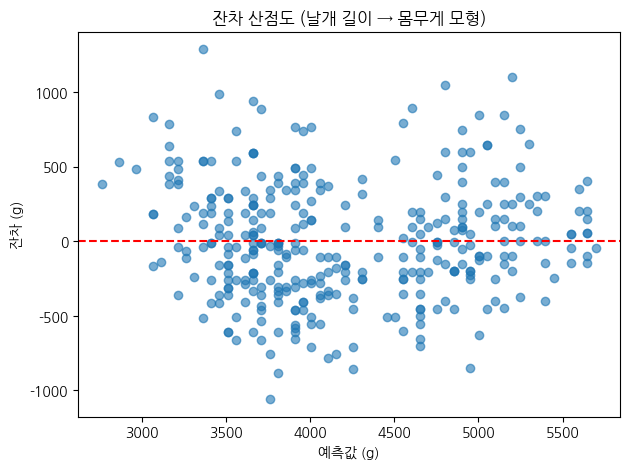

In [27]:
plt.figure(figsize=(7, 5))
plt.scatter(pred, resid, alpha=0.6)
plt.axhline(0, color='red', linestyle='--')
plt.title('잔차 산점도 (날개 길이 → 몸무게 모형)')
plt.xlabel('예측값 (g)')
plt.ylabel('잔차 (g)')
plt.show()

### Q4 · 등분산성을 숫자로 검정해 봅시다

- **브루쉬-페이건 검정**으로 등분산성을 확인하세요.

- H₀는 "등분산이다"입니다. p-값이 0.05보다 작으면 이분산을 의심합니다.

- 판정 결과를 문장으로 함께 출력하세요.

- `💡 힌트` `het_breuschpagan(잔차, model.model.exog)`는
  `(LM통계량, LM p-값, F통계량, F p-값)`을 돌려줍니다.

In [28]:
bp = het_breuschpagan(resid, model.model.exog)
lm_p = bp[1]
verdict = '이분산 의심 (등분산 기각)' if lm_p < 0.05 else '등분산 가정을 기각하지 못함 (등분산으로 볼 수 있음)'
print(f'LM 통계량 = {bp[0]:.4f}, LM p-값 = {lm_p:.4f}')
print(f'판정: {verdict}')

LM 통계량 = 2.1579, LM p-값 = 0.1418
판정: 등분산 가정을 기각하지 못함 (등분산으로 볼 수 있음)


### Q5 · 문제가 있는 모형과 나란히 비교해 봅시다

- **비교군**으로 `body_mass_g ~ bill_length_mm` 모형을 적합해 `model_bill`로 저장하세요.

- 두 모형의 잔차 산점도를 **나란히** 그리세요.

- 두 모형의 브루쉬-페이건 p-값을 **함께 출력**해 비교하세요.

- `💡 힌트` `fig, ax = plt.subplots(1, 2, figsize=(12, 4))`로 두 그림을 옆으로 배치할 수 있습니다.

날개 길이 모형 브루쉬-페이건 p-값 = 0.1418
부리 길이 모형 브루쉬-페이건 p-값 = 0.0000


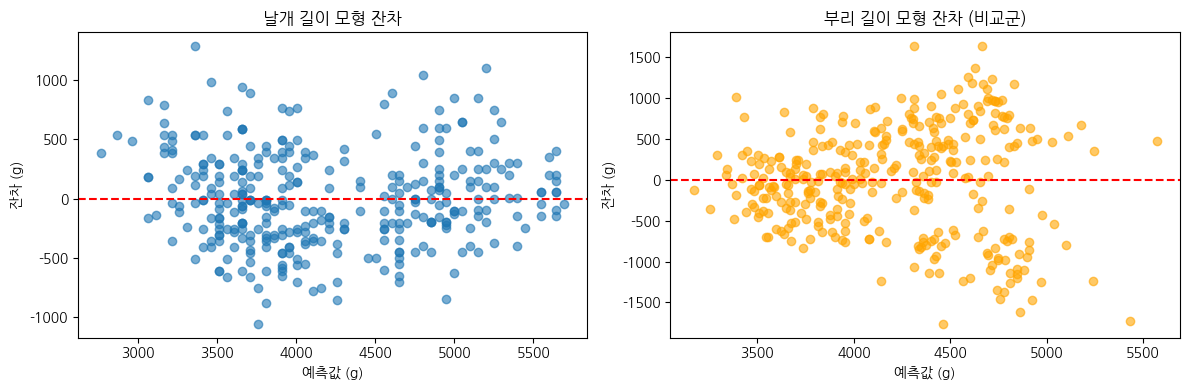

In [29]:
df_bill = penguins.dropna(subset=['body_mass_g', 'bill_length_mm'])
model_bill = smf.ols(formula='body_mass_g ~ bill_length_mm', data=df_bill).fit()
bp_bill = het_breuschpagan(model_bill.resid, model_bill.model.exog)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(pred, resid, alpha=0.6)
ax[0].axhline(0, color='red', linestyle='--')
ax[0].set_title('날개 길이 모형 잔차')
ax[0].set_xlabel('예측값 (g)')
ax[0].set_ylabel('잔차 (g)')
ax[1].scatter(model_bill.fittedvalues, model_bill.resid, alpha=0.6, color='orange')
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_title('부리 길이 모형 잔차 (비교군)')
ax[1].set_xlabel('예측값 (g)')
ax[1].set_ylabel('잔차 (g)')
plt.tight_layout()
plt.show()
print(f'날개 길이 모형 브루쉬-페이건 p-값 = {lm_p:.4f}')
print(f'부리 길이 모형 브루쉬-페이건 p-값 = {bp_bill[1]:.4f}')

### Q6 · 보고 문장으로 정리해 봅시다

- 지금까지의 결과를 종합해, 우리 회귀모형을 보고서에 어떻게 적을지 **한 문장**으로 쓰세요.

- **기울기 + 유의성 + 설명력 + 진단 결과**를 모두 담아 보세요.

In [30]:
# 문제 5 · Q6
# 보고 문장: 날개 길이가 1mm 길어질 때 몸무게는 평균 약 49.7g 늘어나며(p < 0.001), 날개 길이는 몸무게 변동의 약 75.9%를 설명하고, 잔차 산점도와 브루쉬-페이건 검정(p = 0.142)에서 등분산성을 위반한다는 증거가 없어 이 해석을 신뢰할 수 있다.
print('보고 문장 작성 완료')

보고 문장 작성 완료


### 💬 정리 · 결과를 말로 설명해 보기

- Q3·Q4에서 우리 모형의 잔차는 어떤 상태였나요? 이 결과를 근거로 문제 3·4의 해석을 신뢰할 수 있을까요?

- Q5의 두 잔차 산점도는 어떻게 달랐나요? 비교군에서 관찰된 모양을 강의에서 배운 용어로 무엇이라 부르나요?

- 비교군처럼 등분산성이 깨졌을 때, **잘못된 것은 기울기 값 자체인가요, 아니면 그 값의 통계적 해석인가요?**

- R²가 1이 아니라는 것은 설명되지 않은 변동이 남아 있다는 뜻입니다. `penguins` 안에서 몸무게에 영향을 줄 만한데 우리 모델이 놓치고 있는 변수는 무엇일까요?

- 그 변수들을 모델에 함께 넣으려면 어떤 분석이 필요할까요?

<details>
<summary>(클릭) 💡 생각의 갈피</summary>

- 강의 7장은 이렇게 적었습니다 — _"파라미터 값이 잘못되었다는 뜻이 아니라, 이 값의 통계적 해석(유의성·신뢰구간)과 예측 결과를 신뢰할 수 없다는 의미"_. 세 번째 질문의 답이 여기 있습니다.

- 비교군의 잔차가 퍼지는 모양을 강의의 3케이스 그림(정규성 O·등분산 O / X·O / O·X)과 맞춰 보세요.

- 놓친 변수 후보는 문제 1의 그림에 이미 있습니다. 그 변수를 모델에 함께 넣는 분석의 이름은 다음 8장의 제목입니다.

</details>

In [34]:
# 문제 5 · 정리
# 1) 우리 모형의 잔차는 0 주위에 고르게 퍼져 있고 깔때기 모양이 없었다. 브루쉬-페이건 p-값도 0.142로 큰 편이라 등분산을 의심할 근거가 없다. 따라서 문제 3·4의 해석을 신뢰할 수 있다.
# 2) 비교군(부리 길이 모형)의 잔차 폭이 예측값에 따라 달라졌다. 이러한 모양을 이분산성(등분산성 위반)이라고 부른다. 브루쉬-페이건 p-값도 0.0000으로 매우 작았다.
# 3) 기울기 값 자체는 그대로이고, 잘못되는 것은 그 값의 통계적 해석(p-값과 신뢰구간)이다. 등분산이 깨지면 오차 크기 계산이 틀려서 유의성 판단을 믿기 어렵다.
# 4) 놓친 변수는 종(species), 성별(sex), 부리 길이·두께, 섬(island) 등이다. 종마다 체격이 다르기 때문에 몸무게에 영향을 줄 가능성이 크다.
# 5) 설명변수를 여러 개 넣는 다중회귀분석이 필요하다. 종과 성별 같은 범주형 변수는 더미 변수로 바꿔 넣으면 된다.